# Phase 24 — Robustness Checks & Error Analysis

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Analyze the Phase 23 held-out predictions descriptively, assess error concentration by ticker and time, inspect return/prediction distributions, compare simple diagnostic slices, and check whether overlapping forward-return windows complicate interpretation.

**Critical safeguards**
- This notebook does not retrain models, select features, or tune hyperparameters using test results.
- Test-set analysis is descriptive only; do not use it to make new modeling choices and then report the same test set as an untouched final holdout.
- The 3-month target uses 63 future observations per ticker, so adjacent targets overlap heavily.
- This is historical research, not investment advice.

## 1. Setup and locate Phase 23 outputs

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PRED_REL = Path("data/processed/final_evaluation/asx_3m_final_test_predictions.csv")
SUMMARY_REL = Path("reports/final_model_evaluation/phase23_final_model_evaluation_summary.json")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / PRED_REL).exists() and (p / SUMMARY_REL).exists():
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and (p / PRED_REL).exists() and (p / SUMMARY_REL).exists():
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Phase 23 predictions and summary. "
        "Confirm Phase 23 completed and run this notebook from the project or notebooks folder."
    )
PRED_PATH = PROJECT_ROOT / PRED_REL
SUMMARY_PATH = PROJECT_ROOT / SUMMARY_REL
OUT = PROJECT_ROOT / "reports" / "robustness_error_analysis"
OUT.mkdir(parents=True, exist_ok=True)

with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
    phase23_summary = json.load(f)
pred = pd.read_csv(PRED_PATH, low_memory=False)
pred.columns = [str(c).strip().lower() for c in pred.columns]
for c in ["date", "target_endpoint_date_3m"]:
    if c in pred.columns:
        pred[c] = pd.to_datetime(pred[c], errors="coerce")
required = {"ticker", "date", "target_endpoint_date_3m", "forward_return_3m", "predicted_forward_return_3m"}
missing = required - set(pred.columns)
if missing:
    raise ValueError(f"Phase 23 prediction file missing columns: {sorted(missing)}")
pred["ticker"] = pred["ticker"].astype(str).str.strip().str.upper()
pred["forward_return_3m"] = pd.to_numeric(pred["forward_return_3m"], errors="coerce")
pred["predicted_forward_return_3m"] = pd.to_numeric(pred["predicted_forward_return_3m"], errors="coerce")
pred = pred.dropna(subset=["ticker", "date", "forward_return_3m", "predicted_forward_return_3m"]).copy()
pred["residual"] = pred["forward_return_3m"] - pred["predicted_forward_return_3m"]
pred["absolute_error"] = pred["residual"].abs()
pred["squared_error"] = pred["residual"] ** 2
print("Project root:", PROJECT_ROOT)
print("Prediction rows:", len(pred), "| Tickers:", pred["ticker"].nunique())
print("Selected model:", phase23_summary.get("selected_model_by_validation_mae"))

Project root: e:\Projects\Australian Stock Market Data Science Project
Prediction rows: 9412 | Tickers: 52
Selected model: Ridge Regression


## 2. Recalculate overall test metrics

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y = pred["forward_return_3m"]
p = pred["predicted_forward_return_3m"]
overall = {
    "n": int(len(pred)),
    "tickers": int(pred["ticker"].nunique()),
    "date_min": str(pred["date"].min()),
    "date_max": str(pred["date"].max()),
    "actual_mean": float(y.mean()),
    "predicted_mean": float(p.mean()),
    "MAE": float(mean_absolute_error(y, p)),
    "RMSE": float(np.sqrt(mean_squared_error(y, p))),
    "R2": float(r2_score(y, p)),
    "mean_bias_predicted_minus_actual": float(p.mean() - y.mean()),
    "median_absolute_error": float(pred["absolute_error"].median()),
    "p90_absolute_error": float(pred["absolute_error"].quantile(0.90)),
    "p95_absolute_error": float(pred["absolute_error"].quantile(0.95))
}
print(json.dumps(overall, indent=2))
with open(OUT / "phase24_overall_error_summary.json", "w", encoding="utf-8") as f:
    json.dump(overall, f, indent=2, default=str)

{
  "n": 9412,
  "tickers": 52,
  "date_min": "2025-11-03 00:00:00",
  "date_max": "2026-07-22 00:00:00",
  "actual_mean": -0.009887806217044012,
  "predicted_mean": 0.032577178255003364,
  "MAE": 0.14542968580413784,
  "RMSE": 0.18704924191415379,
  "R2": -0.06863781600094598,
  "mean_bias_predicted_minus_actual": 0.04246498447204738,
  "median_absolute_error": 0.11606699727281106,
  "p90_absolute_error": 0.31990548102527316,
  "p95_absolute_error": 0.3732591550460075
}


## 3. Error concentration by ticker

,ticker,n,actual_mean_return,predicted_mean_return,MAE,RMSE,bias_predicted_minus_actual
8,ASG,181,-0.303687,0.048994,0.352682,0.363343,0.352682
43,STP,181,-0.280447,0.009446,0.293016,0.319515,0.289893
27,KMD,181,-0.213622,0.018421,0.274676,0.355254,0.232043
36,PWR,181,-0.232275,0.023743,0.258991,0.276495,0.256018
5,ANN,181,0.078221,0.031547,0.229782,0.263413,-0.046674
21,GNC,181,-0.037982,0.022217,0.226985,0.248820,0.060199
17,DDR,181,0.154195,0.038525,0.226222,0.255833,-0.115670
34,PLS,181,0.050650,0.132057,0.221301,0.256559,0.081407
35,PTL,181,-0.203419,0.008301,0.219926,0.246229,0.211720
47,VEA,181,0.171561,0.031046,0.219872,0.262688,-0.140515


,ticker,n,actual_mean_return,predicted_mean_return,MAE,RMSE,bias_predicted_minus_actual
11,BEN,181,0.007879,0.027430,0.039520,0.051301,0.019551
16,COL,181,0.040112,0.031797,0.047969,0.056014,-0.008316
6,ANZ,181,0.024645,0.040357,0.056264,0.067334,0.015712
51,WPR,181,-0.021727,0.031499,0.057470,0.072031,0.053226
42,SIG,181,-0.018654,0.029278,0.057651,0.070533,0.047932
13,BOQ,181,0.017855,0.028057,0.061416,0.073335,0.010202
22,HLI,181,0.050766,0.034606,0.066280,0.078711,-0.016161
24,IAG,181,0.032087,0.026276,0.075048,0.090139,-0.005811
48,WBC,181,-0.021335,0.037138,0.078052,0.094735,0.058473
12,BGA,181,0.024609,0.033869,0.079094,0.096211,0.009260


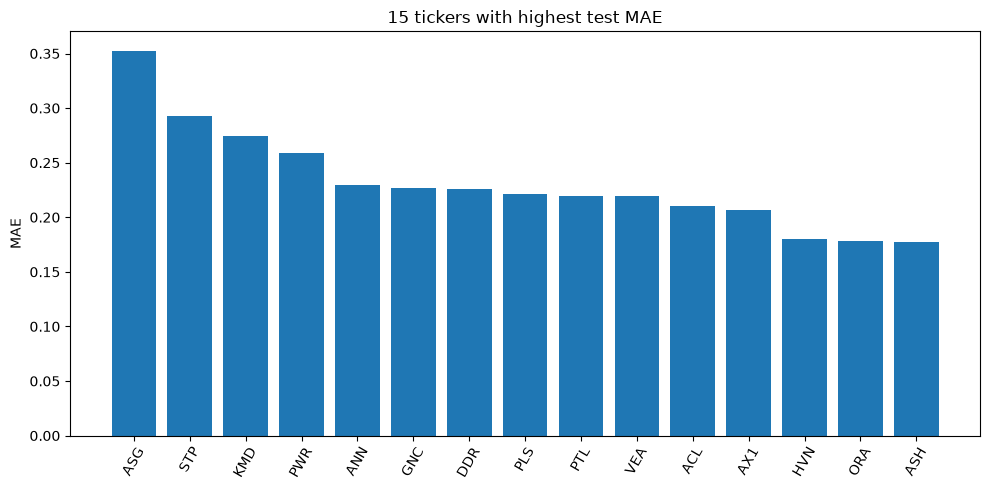

In [3]:
ticker_rows = []
for ticker, g in pred.groupby("ticker"):
    ticker_rows.append({
        "ticker": ticker,
        "n": len(g),
        "actual_mean_return": g["forward_return_3m"].mean(),
        "predicted_mean_return": g["predicted_forward_return_3m"].mean(),
        "MAE": g["absolute_error"].mean(),
        "RMSE": np.sqrt(g["squared_error"].mean()),
        "bias_predicted_minus_actual": g["predicted_forward_return_3m"].mean() - g["forward_return_3m"].mean()
    })
ticker_report = pd.DataFrame(ticker_rows).sort_values("MAE", ascending=False)
display(ticker_report.head(15))
display(ticker_report.tail(15).sort_values("MAE"))
ticker_report.to_csv(OUT / "error_metrics_by_ticker.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
plot_ticker = ticker_report.sort_values("MAE", ascending=False).head(15)
ax.bar(plot_ticker["ticker"], plot_ticker["MAE"])
ax.set_title("15 tickers with highest test MAE")
ax.set_ylabel("MAE")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(OUT / "highest_error_tickers.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Error patterns over calendar time

,month,n,actual_mean_return,predicted_mean_return,MAE,RMSE,bias_predicted_minus_actual
0,2025-11,1040,-0.020787,0.020787,0.134537,0.169961,0.041575
1,2025-12,1092,-0.064218,0.038996,0.147676,0.186252,0.103214
2,2026-01,1040,-0.068537,0.038548,0.161053,0.205991,0.107085
3,2026-02,1040,-0.085552,0.030815,0.176645,0.218574,0.116367
4,2026-03,1144,-0.012372,0.039925,0.151771,0.194299,0.052297
5,2026-04,1040,0.014075,0.034945,0.122299,0.161357,0.020871
6,2026-05,1092,0.086130,0.030027,0.141506,0.181527,-0.056103
7,2026-06,1092,0.047568,0.026257,0.143035,0.186622,-0.021311
8,2026-07,832,0.014966,0.032208,0.126036,0.167281,0.017242


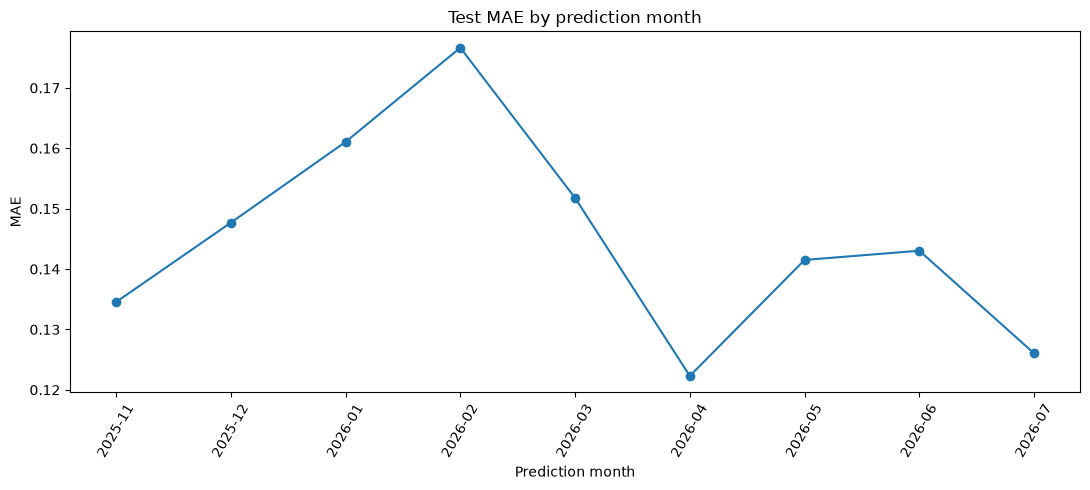

In [4]:
pred["calendar_month"] = pred["date"].dt.to_period("M").astype(str)
monthly_rows = []
for month, g in pred.groupby("calendar_month"):
    monthly_rows.append({
        "month": month, "n": len(g),
        "actual_mean_return": g["forward_return_3m"].mean(),
        "predicted_mean_return": g["predicted_forward_return_3m"].mean(),
        "MAE": g["absolute_error"].mean(),
        "RMSE": np.sqrt(g["squared_error"].mean()),
        "bias_predicted_minus_actual": g["predicted_forward_return_3m"].mean() - g["forward_return_3m"].mean()
    })
monthly_report = pd.DataFrame(monthly_rows).sort_values("month")
display(monthly_report)
monthly_report.to_csv(OUT / "error_metrics_by_month.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_report["month"], monthly_report["MAE"], marker="o")
ax.set_title("Test MAE by prediction month")
ax.set_ylabel("MAE")
ax.set_xlabel("Prediction month")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(OUT / "test_mae_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Inspect return and residual distributions

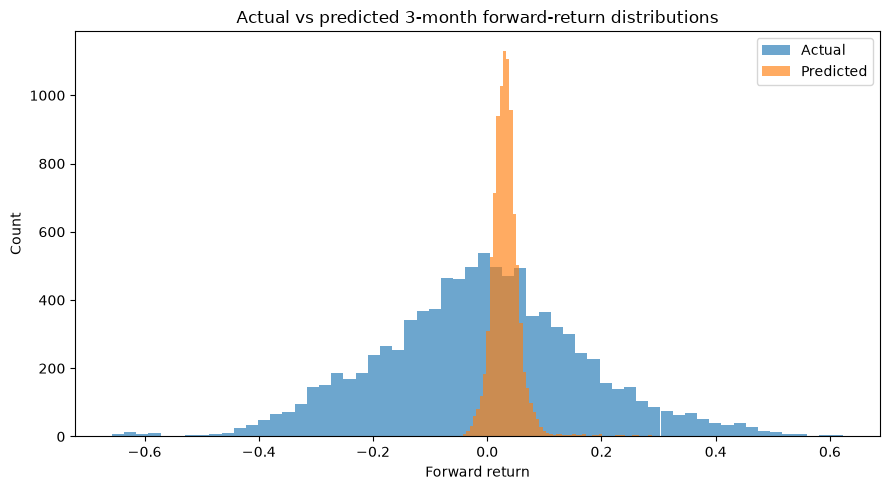

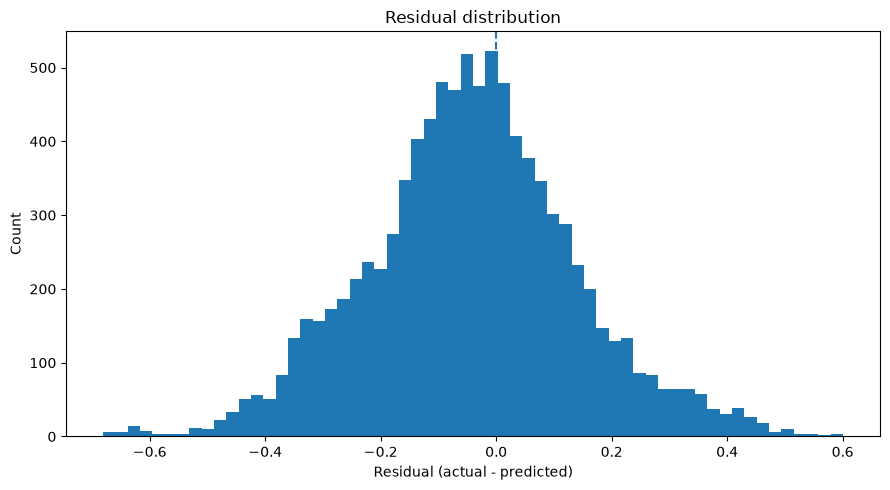

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
forward_return_3m,9412.0,-0.009888,0.180952,-0.657354,-0.419852,-0.304348,-0.123027,-0.009421,0.101037,0.298895,0.442752,0.623638
predicted_forward_return_3m,9412.0,0.032577,0.026888,-0.059507,-0.020865,-0.002223,0.017832,0.030946,0.043814,0.069681,0.121189,0.288130
residual,9412.0,-0.042465,0.182175,-0.680531,-0.460593,-0.341566,-0.152993,-0.042852,0.068767,0.271779,0.415978,0.600588
absolute_error,9412.0,0.145430,0.117640,0.000009,0.001765,0.009518,0.053073,0.116067,0.212568,0.373259,0.480736,0.680531


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pred["forward_return_3m"], bins=60, alpha=0.65, label="Actual")
ax.hist(pred["predicted_forward_return_3m"], bins=60, alpha=0.65, label="Predicted")
ax.set_title("Actual vs predicted 3-month forward-return distributions")
ax.set_xlabel("Forward return")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "actual_predicted_return_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pred["residual"], bins=60)
ax.axvline(0, linestyle="--")
ax.set_title("Residual distribution")
ax.set_xlabel("Residual (actual - predicted)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUT / "residual_distribution_detailed.png", dpi=150, bbox_inches="tight")
plt.show()

distribution = pred[["forward_return_3m", "predicted_forward_return_3m", "residual", "absolute_error"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
display(distribution)
distribution.to_csv(OUT / "return_residual_distribution_stats.csv")

## 6. Diagnostic slices by realized-return regime

In [6]:
# These bins describe the held-out outcomes; they are for retrospective diagnostics only.
pred["realized_return_regime"] = pd.cut(
    pred["forward_return_3m"],
    bins=[-np.inf, -0.20, -0.05, 0.05, 0.20, np.inf],
    labels=["below -20%", "-20% to -5%", "-5% to 5%", "5% to 20%", "above 20%"],
    right=False
)
regime_report = pred.groupby("realized_return_regime", observed=False).apply(
    lambda g: pd.Series({
        "n": len(g),
        "actual_mean": g["forward_return_3m"].mean(),
        "predicted_mean": g["predicted_forward_return_3m"].mean(),
        "MAE": g["absolute_error"].mean(),
        "RMSE": np.sqrt(g["squared_error"].mean()),
        "bias_predicted_minus_actual": g["predicted_forward_return_3m"].mean() - g["forward_return_3m"].mean()
    }), include_groups=False
).reset_index()
display(regime_report)
regime_report.to_csv(OUT / "error_by_realized_return_regime.csv", index=False)

,realized_return_regime,n,actual_mean,predicted_mean,MAE,RMSE,bias_predicted_minus_actual
0,below -20%,1348.0,-0.296822,0.033340,0.330162,0.340951,0.330162
1,-20% to -5%,2426.0,-0.115045,0.031297,0.146343,0.154052,0.146343
2,-5% to 5%,2315.0,0.000213,0.031872,0.038453,0.047446,0.031658
3,5% to 20%,2272.0,0.114690,0.032991,0.084213,0.096430,-0.081699
4,above 20%,1051.0,0.309308,0.035214,0.274358,0.290488,-0.274094


## 7. Dependence from overlapping 63-observation targets

In [7]:
# Adjacent rows for the same ticker have overlapping forward-return windows.
# Count target windows that overlap the prior row's window for each ticker.
pred_sorted = pred.sort_values(["ticker", "date"]).copy()
pred_sorted["previous_endpoint"] = pred_sorted.groupby("ticker")["target_endpoint_date_3m"].shift(1)
pred_sorted["overlap_with_previous_target"] = (
    pred_sorted["previous_endpoint"].notna() &
    (pred_sorted["date"] <= pred_sorted["previous_endpoint"])
)
overlap_summary = {
    "rows": int(len(pred_sorted)),
    "overlapping_with_previous_target_rows": int(pred_sorted["overlap_with_previous_target"].sum()),
    "overlap_fraction_after_first_ticker_rows": float(
        pred_sorted["overlap_with_previous_target"].sum() /
        max(1, pred_sorted.groupby("ticker").size().sub(1).sum())
    ),
    "interpretation": "Overlapping labels make row-level errors dependent; standard errors and apparent sample size should not be treated as independent observations."
}
print(json.dumps(overlap_summary, indent=2))
with open(OUT / "overlapping_target_window_diagnostic.json", "w", encoding="utf-8") as f:
    json.dump(overlap_summary, f, indent=2)

{
  "rows": 9412,
  "overlapping_with_previous_target_rows": 9360,
  "overlap_fraction_after_first_ticker_rows": 1.0,
  "interpretation": "Overlapping labels make row-level errors dependent; standard errors and apparent sample size should not be treated as independent observations."
}


## 8. Write a concise findings report

In [8]:
worst = ticker_report.head(5)[["ticker", "MAE"]].to_dict(orient="records")
best = ticker_report.tail(5).sort_values("MAE")[["ticker", "MAE"]].to_dict(orient="records")
highest_month = monthly_report.sort_values("MAE", ascending=False).head(1).to_dict(orient="records")
lowest_month = monthly_report.sort_values("MAE", ascending=True).head(1).to_dict(orient="records")
findings = {
    "phase": 24,
    "overall": overall,
    "highest_error_tickers": worst,
    "lowest_error_tickers": best,
    "highest_error_month": highest_month,
    "lowest_error_month": lowest_month,
    "overlap_diagnostic": overlap_summary,
    "interpretation": [
        "These are descriptive diagnostics of the held-out test period, not a new tuning loop.",
        "Forward-return targets overlap over 63 observations, so errors are temporally dependent.",
        "The baseline outperformed Ridge on the Phase 23 test metrics; do not claim the current model adds predictive value.",
        "Ticker/month patterns may be unstable and should not be interpreted as future forecasts."
    ],
    "warning": "Historical research only; no investment advice."
}
with open(OUT / "phase24_robustness_error_analysis_summary.json", "w", encoding="utf-8") as f:
    json.dump(findings, f, indent=2, default=str)

report_lines = [
    "# Phase 24 — Robustness Checks & Error Analysis",
    "",
    "## Overall",
    f"- Test rows: {overall['n']}",
    f"- Tickers: {overall['tickers']}",
    f"- MAE: {overall['MAE']:.6f}",
    f"- RMSE: {overall['RMSE']:.6f}",
    f"- R²: {overall['R2']:.6f}",
    f"- Mean prediction bias (predicted - actual): {overall['mean_bias_predicted_minus_actual']:.6f}",
    "",
    "## Highest-error tickers",
]
for item in worst:
    report_lines.append(f"- {item['ticker']}: MAE {item['MAE']:.6f}")
report_lines += ["", "## Interpretation", *[f"- {x}" for x in findings["interpretation"]]]
(OUT / "phase24_findings_report.md").write_text("\n".join(report_lines), encoding="utf-8")

print("Saved Phase 24 outputs to:", OUT)
print("Main summary:", OUT / "phase24_robustness_error_analysis_summary.json")
print("Findings report:", OUT / "phase24_findings_report.md")

Saved Phase 24 outputs to: e:\Projects\Australian Stock Market Data Science Project\reports\robustness_error_analysis
Main summary: e:\Projects\Australian Stock Market Data Science Project\reports\robustness_error_analysis\phase24_robustness_error_analysis_summary.json
Findings report: e:\Projects\Australian Stock Market Data Science Project\reports\robustness_error_analysis\phase24_findings_report.md


## 9. Completion checklist
- Review highest-error tickers and months as descriptive findings.
- Inspect actual/predicted distributions and residuals.
- Report overlapping-label dependence.
- Do not retune on this test set.
- Carry the baseline result honestly into the final portfolio report.